this script compares the scientific workforce of countries in international collaboration and domestically. the way of testing it is to bootstrapping researchers from each country and compare the expected results with the actual international workforce.

In [1]:
import pandas as pd
from time import time
import numpy as np
import tqdm
import geopandas as gp
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
import seaborn as sns
import itertools
from matplotlib.lines import Line2D

In [29]:
pub_detail_path='../../data/dropbox/LaborDivision/Data/deriveddata/pub_detail.pkl'
author_path='../../data/dropbox/LaborDivision/Data/deriveddata/authors_ordered.pkl'
author_info_path='../../data/dropbox/LaborDivision/Data/cleanedraw/author_info.pkl'
ingroup_path = '../../data/dropbox/LaborDivision/Data/additionaldata/cntry_classification/cntry_group_meta.csv'

In [3]:
output_path='../../data/dropbox/LaborDivision/Data/deriveddata/national_bootstrapping/national_boostrappting.csv'
plot_path='../../data/dropbox/LaborDivision/figs/national_comparision.pdf'

In [4]:
pub_all=pd.read_pickle(pub_detail_path)

In [5]:
pub_all.head()

,id,year,dis,alpha,teamsize,int
0,38579295,2012,1,no,4,0
1,38579296,2012,120,no,4,0
2,38579297,2012,84,no,4,1
3,38579302,2012,55,no,4,0
4,38579305,2012,43,no,4,0


In [6]:
pub_int=pub_all[pub_all.int==1]
pub_int.head()

,id,year,dis,alpha,teamsize,int
2,38579297,2012,84,no,4,1
14,38579353,2012,132,no,3,1
22,38579379,2012,51,yes,2,1
27,38579408,2012,33,no,4,1
28,38579409,2012,12,no,4,1


In [7]:
author_all=pd.read_pickle(author_path)
author_all.head()

,id,year,dis,cluster_id,role,Code
0,29768068,2008,56,1306275,F,CAN
1,29768068,2008,56,1680670,M,CAN
2,29768068,2008,56,28261869,L,CAN
3,29768070,2008,51,20009795,F,JPN
4,29768070,2008,51,29411586,M,JPN


In [8]:
author_info=pd.read_pickle(author_info_path)
author_info.head()

,cluster_id,yfp,npub,gender
0,689940,2008,1,unk
1,44823147,2008,1,unk
2,27676457,2011,1,M
3,59751143,2018,1,F
4,59894652,2004,8,M


In [9]:
author_all=author_all.merge(pub_all[['id','int']],on=['id']) #add the column to indicate whether the author is international or not
years=author_all.year.unique()
cntrys=author_all.Code.unique()

In [10]:
def return_authors(df,cntry,year,int):
    adf=df[df.year==year]
    adf=adf[adf['Code']==cntry]
    if int==1:
        adf=adf[adf['int']==int]
    return adf[['cluster_id']].drop_duplicates()

In [11]:
def return_author_info(df, info_df):
    ids=df['cluster_id']
    info_select=info_df[info_df['cluster_id'].isin(ids)]
    info_select=info_select[info_select.gender!='unk']
    return info_select

In [12]:
def return_measurement(df):
    #return the median age of first publication year, median number of publication, number of Male and number of Female
    yfp=df['yfp'].median()
    npub=df['npub'].median()
    try:
        male=df['gender'].value_counts()['M']
    except KeyError:
        male=0
    try:
        female=df['gender'].value_counts()['F']
    except KeyError:
        female=0
    return yfp, npub, male, female

In [13]:
def return_sample(df,sample_size):
    return df.sample(n=sample_size, replace=True)

In [14]:
author_all.head()

,id,year,dis,cluster_id,role,Code,int
0,29768068,2008,56,1306275,F,CAN,0
1,29768068,2008,56,1680670,M,CAN,0
2,29768068,2008,56,28261869,L,CAN,0
3,29768070,2008,51,20009795,F,JPN,1
4,29768070,2008,51,29411586,M,JPN,1


In [15]:
author_all=author_all[['cluster_id','Code','year','int']].drop_duplicates()
#author_all=author_all.drop_duplicates(subset=['Code','year','int','cluster_id'])
#author_all['id']=author_all['id'].astype("int64")

In [16]:
author_all=author_all.dropna()
author_info=author_info.dropna()
author_all['cluster_id']=author_all['cluster_id'].astype("int64")
author_info['cluster_id']=author_info['cluster_id'].astype('int64')

In [24]:
result=[]
cntry='JPN'
year=2009
int_author=return_authors(author_all,cntry,year,1)
dom_author=return_authors(author_all,cntry,year,0)
int_author=return_author_info(int_author,author_info)
dom_author=return_author_info(dom_author,author_info)

yfp_raw,npub_raw,male_raw,female_raw=return_measurement(int_author)
result.append([cntry,year,'raw',yfp_raw,npub_raw,male_raw,female_raw])

sample_size=int_author.shape[0]
for i in range(10):
    sample_df=return_sample(dom_author,sample_size)
    yfp_s,npub_s,male_s,female_s=return_measurement(sample_df)
    result.append([cntry,year,'sample',yfp_s,npub_s,male_s,female_s])

"sample_size=int_author.shape[0]\nfor i in range(10):\n    sample_df=return_sample(dom_author,sample_size)\n    yfp_s,npub_s,male_s,female_s=return_measurement(sample_df)\n    result.append([cntry,year,'sample',yfp_s,npub_s,male_s,female_s])"

In [17]:
result=[]
for year,cntry in tqdm.tqdm(itertools.product(years,cntrys),total=len(years)*len(cntrys)):
    int_author=return_authors(author_all,cntry,year,1)
    dom_author=return_authors(author_all,cntry,year,0)
    
    if len(dom_author)>0 and len(int_author)>0:

        int_author=return_author_info(int_author,author_info)
        dom_author=return_author_info(dom_author,author_info)

        yfp_raw,npub_raw,male_raw,female_raw=return_measurement(int_author)
        result.append([cntry,year,'raw',yfp_raw,npub_raw,male_raw,female_raw])

        sample_size=int_author.shape[0]
        for i in range(10):
            sample_df=return_sample(dom_author,sample_size)
            yfp_s,npub_s,male_s,female_s=return_measurement(sample_df)
            result.append([cntry,year,'sample',yfp_s,npub_s,male_s,female_s])
    else:
        result.append([cntry,year,'invalid'])

100%|██████████| 2626/2626 [1:46:33<00:00,  2.43s/it]


In [18]:
pd.DataFrame(result,columns=['cntry','year','source','yfp','npub','male','female']
            ).to_csv(output_path,index=False)

In [20]:
boot_df=pd.read_csv(output_path)

In [21]:
boot_df

,cntry,year,source,yfp,npub,male,female
0,CAN,2008,raw,2002.0,14.0,14219.0,6708.0
1,CAN,2008,sample,2005.0,7.0,13119.0,7808.0
2,CAN,2008,sample,2005.0,7.0,13244.0,7683.0
3,CAN,2008,sample,2005.0,7.0,13110.0,7817.0
4,CAN,2008,sample,2005.0,7.0,13085.0,7842.0
...,...,...,...,...,...,...,...
28201,FRO,2020,sample,2003.0,15.5,8.0,6.0
28202,FRO,2020,sample,1997.5,10.5,12.0,2.0
28203,FRO,2020,sample,2000.0,18.5,13.0,1.0
28204,FRO,2020,sample,2004.5,9.0,10.0,4.0


In [37]:
agg_df=boot_df.groupby(['cntry','year','source']).agg({'yfp':'mean',
                                                      'npub':'mean',
                                                      'male':'mean',
                                                      'female':'mean'}).reset_index()

In [38]:
agg_df=agg_df.dropna()
agg_df = agg_df.pivot(index=['cntry','year'],columns='source').reset_index()

In [39]:
agg_df.columns=agg_df.columns.map('_'.join)

In [40]:
agg_df

,cntry_,year_,yfp_raw,yfp_sample,npub_raw,npub_sample,male_raw,male_sample,female_raw,female_sample
0,ABW,2014,2014.0,2014.00,18.0,18.00,1.0,1.0,0.0,0.0
1,ABW,2016,2016.0,2015.80,1.0,3.00,4.0,3.8,1.0,1.2
2,ABW,2017,2017.0,2017.00,1.0,1.40,4.0,4.2,5.0,4.8
3,ABW,2018,2017.0,2017.40,1.0,1.00,1.0,1.0,2.0,2.0
4,ABW,2019,2016.0,2017.20,3.0,3.40,3.0,3.8,2.0,1.2
...,...,...,...,...,...,...,...,...,...,...
2528,ZWE,2016,2013.0,2014.10,5.0,4.30,180.0,188.7,127.0,118.3
2529,ZWE,2017,2014.0,2014.15,6.0,4.70,225.0,230.8,139.0,133.2
2530,ZWE,2018,2015.0,2015.75,5.0,4.05,251.0,252.8,153.0,151.2
2531,ZWE,2019,2015.0,2016.20,5.0,3.50,260.0,274.5,175.0,160.5


In [51]:
agg_df['year_diff']=agg_df['yfp_raw']-agg_df['yfp_sample']
agg_df['npub_diff']=(agg_df['npub_raw']-agg_df['npub_sample'])
#agg_df['npub_diff']=(agg_df['npub_raw']-agg_df['npub_sample'])/(agg_df['npub_sample'])
agg_df['male_diff']=np.log(agg_df['male_raw']/agg_df['male_sample'])
agg_df['female_diff']=np.log(agg_df['female_raw']/agg_df['female_sample'])

/home/miaoli/conda/envs/funding/lib/python3.8/site-packages/pandas/core/arraylike.py:358: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [42]:
ingroup_df=pd.read_csv(ingroup_path)
ingroup_df=ingroup_df[['Code','ST']]
ingroup_df=ingroup_df.drop_duplicates()
ingroup_df=ingroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
ingroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [43]:
agg_df=agg_df.merge(ingroup_df,left_on='cntry_',right_on='Code')

In [34]:
def plot(df,ycol,ax,ylabel):
    data=df[['year_','ST',ycol]]
    data=data.replace([np.inf, -np.inf], np.nan)
    data=data.dropna()
    hue_color={'Advanced':'#E01A27','Proficient':'#F88A4D','Developing':'#5DC97C','Lagging':'#23A5D9'}
    sns.lineplot(x='year_',y=ycol,hue='ST',data=data,palette=hue_color,legend=False,ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel,fontsize=12)
    return ax

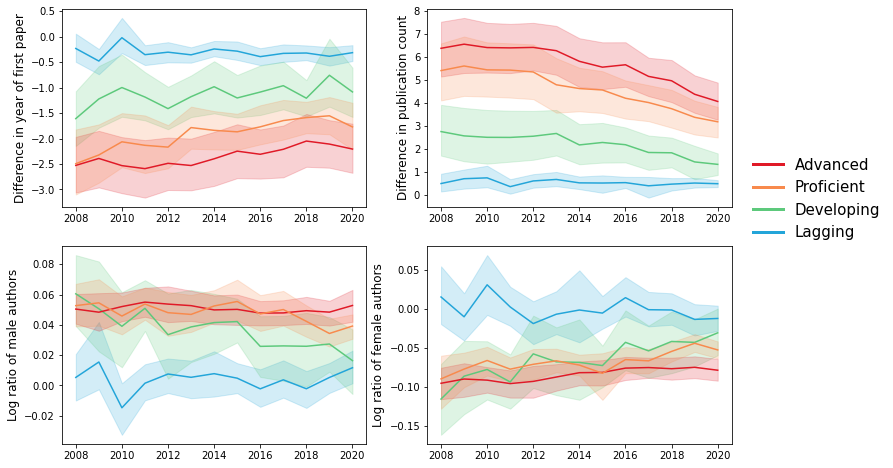

In [53]:
fig,ax=plt.subplots(nrows=2,ncols=2,figsize=(12,8))
ax0=plot(agg_df,'year_diff',ax[0][0],'Difference in year of first paper')
ax1=plot(agg_df,'npub_diff',ax[0][1],'Difference in publication count')
ax2=plot(agg_df,'male_diff',ax[1][0],'Log ratio of male authors')
ax3=plot(agg_df,'female_diff',ax[1][1],'Log ratio of female authors')

colors = ['#E01A27', '#F88A4D', '#5DC97C','#23A5D9']
lines = [Line2D([0], [0], color=c, linewidth=3, linestyle='-') for c in colors]
labels = ['Advanced', 'Proficient', 'Developing','Lagging']
plt.legend(lines, labels,loc=[1.05,1],frameon=False,fontsize=15)
plt.savefig(plot_path,bbox_inches='tight')